In [1]:
!pip install ultralytics
!pip install opencv-python
!pip install matplotlib
!pip install roboflow


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.1/46.1 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 285.0/285.0 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 78.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 130.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.6 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 5.0.0.93
    Uninstalling opencv-python-headless-5.0.0.93:
      Successfully uninstalled opencv-python-headless-5.0.0.93
  Attempting uninstall: typer
    Found existing installation: typer 0.26.8
    Uninstalling typer-0.26.8:
      Successfully uninstalled typer-0.26.8


## data set loading

In [2]:
from roboflow import Roboflow
rf = Roboflow(api_key="J6HUFDSGkvjru3ddznsL")
project = rf.workspace("sumit-kumar-99-s-workspace").project("somke-and-fire-seq-auoic")
version = project.version(1)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Somke-and-fire-seq-1 in yolov8:: 100%|██████████| 3693/3693 [00:00<00:00, 4247.83it/s]


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
import os

print(os.listdir(dataset.location))

['train', 'valid', 'data.yaml', 'test', 'README.dataset.txt', 'README.roboflow.txt']


In [4]:
with open(dataset.location + "/data.yaml") as f:
    print(f.read())

names:
- fire
- smoke
nc: 2
roboflow:
  license: CC BY 4.0
  project: somke-and-fire-seq-auoic
  url: https://universe.roboflow.com/sumit-kumar-99-s-workspace/somke-and-fire-seq-auoic/dataset/1
  version: 1
  workspace: sumit-kumar-99-s-workspace
test: ../test/images
train: ../train/images
val: ../valid/images



In [6]:
dataset.location

'/content/Somke-and-fire-seq-1'

In [7]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16
)

Ultralytics 8.4.107 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Somke-and-fire-seq-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=F

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e871bfc5010>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [9]:
import os

print(os.getcwd())

/content


In [10]:
import os

print(os.listdir())

['.config', 'yolov8n.pt', 'Somke-and-fire-seq-1', 'runs', 'yolo26n.pt', 'sample_data']


In [11]:
import os

for root, dirs, files in os.walk("/content"):
    if "best.pt" in files:
        print(os.path.join(root, "best.pt"))

/content/runs/detect/train-2/weights/best.pt


In [16]:
from ultralytics import YOLO

# Load trained model
model = YOLO("runs/detect/train-2/weights/best.pt")

# Predict on an image
results = model.predict(
    source='runs/detect/train-2/val_batch0_pred.jpg',
    conf=0.25,
    save=True
)


image 1/1 /content/runs/detect/train-2/val_batch0_pred.jpg: 640x640 4 fires, 4 smokes, 7.2ms
Speed: 3.3ms preprocess, 7.2ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


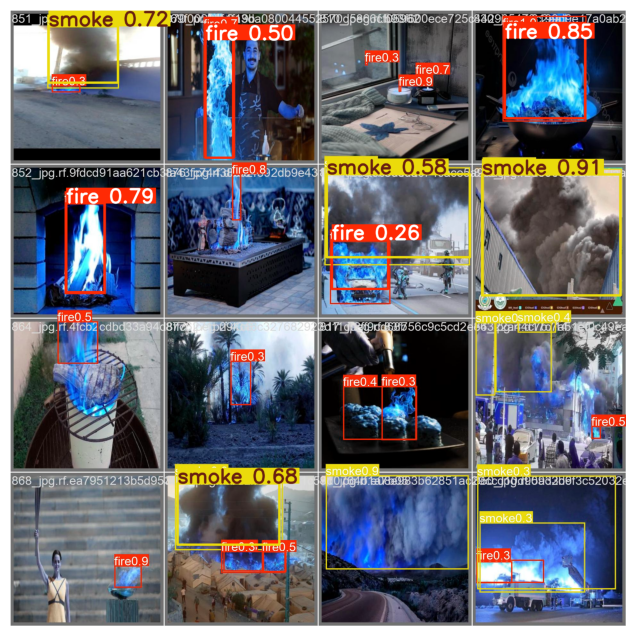

In [18]:
import matplotlib.pyplot as plt

img = results[0].plot()   # Image with bounding boxes

plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

In [19]:
from google.colab import drive
drive.mount('/content/drive')

!cp runs/detect/train-2/weights/best.pt /content/drive/MyDrive/

Mounted at /content/drive
